In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch


inputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case1_ II-IV Semiconductor NCs/Dataset/inputs_normalized.csv')
outputs = pd.read_csv('/Users/mx23826/Documents/ML_winter_school/BoFlex/SDL Case Studies/Inorganic Nanomaterials/Case1_ II-IV Semiconductor NCs/Dataset/outputs_normalized.csv')
total = pd.concat([inputs, outputs], axis=1)


train_X_df, test_X_df, train_y_df, test_y_df = train_test_split(inputs,outputs, test_size=0.9, random_state=42)
train_X_df, external_test_X_df, train_y_df, external_test_y_df = train_test_split(train_X_df, train_y_df, test_size=0.95, random_state=42) # Create external test set for model evaluation

train_X = torch.tensor(train_X_df.to_numpy())
test_X = torch.tensor(test_X_df.to_numpy())

train_y = torch.tensor(train_y_df.to_numpy())
test_y = torch.tensor(test_y_df.to_numpy())

external_test_X = torch.tensor(external_test_X_df.to_numpy())
external_test_y = torch.tensor(external_test_y_df.to_numpy())

X_tensor = torch.tensor(inputs.to_numpy())
y_tensor = torch.tensor(outputs.to_numpy())

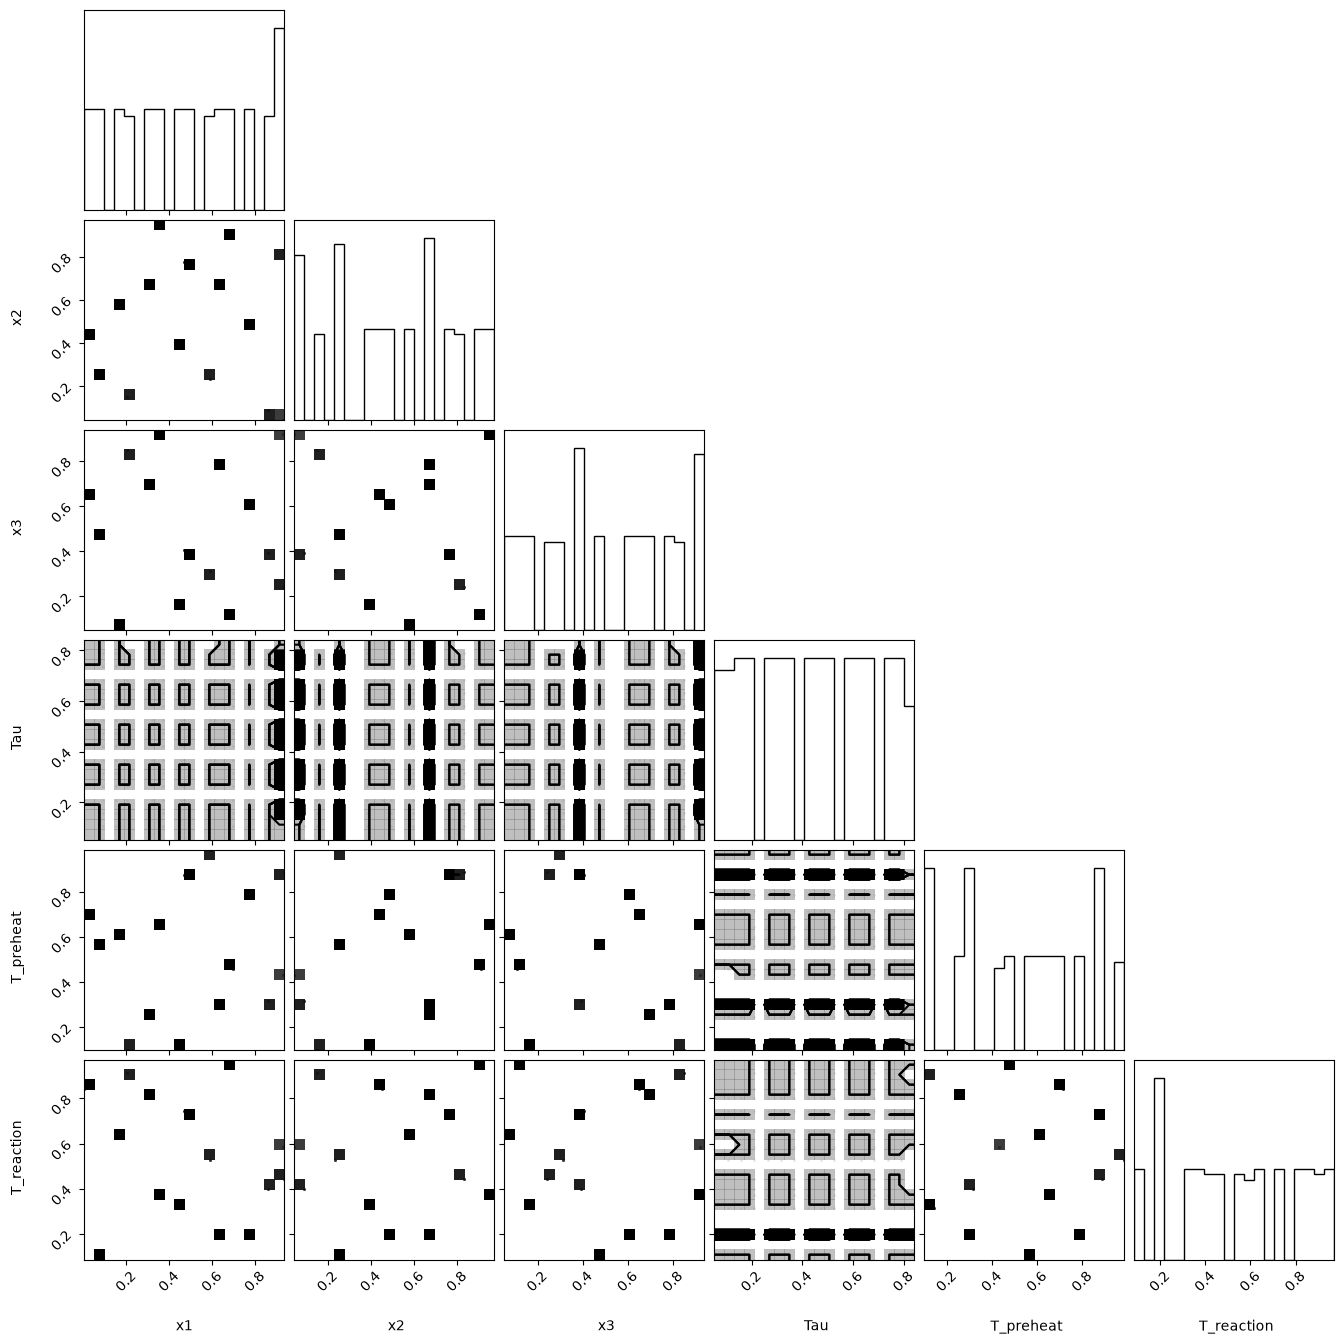

In [2]:
import corner

fig = corner.corner(inputs, labels=inputs.columns)

In [ ]:
from botorch.models.transforms import Normalize,Standardize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
from botorch.acquisition.joint_entropy_search import qJointEntropySearch
from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.optim import optimize_acqf, optimize_acqf_discrete
from botorch.models import SingleTaskGP
from tqdm import tqdm
import torch.nn as nn


torch.manual_seed(42)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

optimisations = len(test_X)

target_preds = []

for i in tqdm(range(optimisations), total=optimisations):
    model=SingleTaskGP(train_X,train_y[:, 0].unsqueeze(1),
                    outcome_transform=Standardize(m=1)
                    )
    
    optimal_inputs = train_X[train_y[:, 0].argmax()].unsqueeze(0)
    acq = qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)

    model=SingleTaskGP(train_X,train_y[:, 0].unsqueeze(1),
                    outcome_transform=Standardize(m=1)
                    )

    fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood,model))

    acq=qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)

    new_X,_=optimize_acqf_discrete( # Discrete acqf required to confine model to known experiments
                                    acq_function=acq, 
                                    choices=test_X,
                                    q=1,
    )

    hit = (test_X == new_X).all(dim=1)

    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))

    test_X = test_X[~hit]
    test_y = test_y[~hit]
    
    target_preds.append(model.posterior(external_test_X).mean) # Make predictions for external test set
    

  0%|          | 0/61 [00:00<?, ?it/s]

 59%|█████▉    | 36/61 [00:07<00:06,  3.84it/s]

/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/torch/nn/modules/loss.py:133: UserWarning: Using a target size (torch.Size([22, 2])) that is different to the input size (torch.Size([22, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)


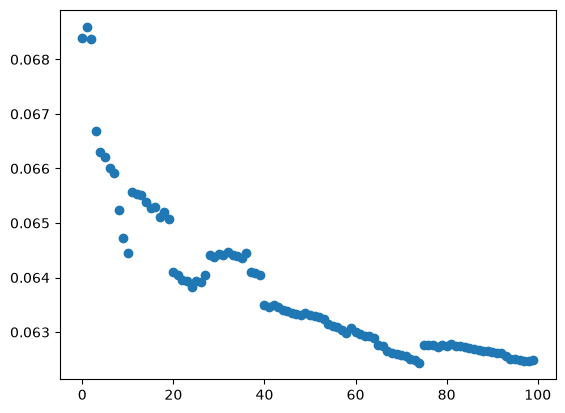

In [ ]:
import matplotlib.pyplot as plt

MAEs = [MAE(pred, external_test_y).detach() for pred in target_preds]
plt.scatter(range(len(MAEs)), MAEs)